# Dossier D03: Distribución de agua purificada en bidones

**Investigación de Operaciones II (3406C322), Proyecto Unidad 2.** Aguas del Desierto Ltda., Antofagasta, La Negra y faenas cercanas, Región de Antofagasta (caso ficticio).

Cuaderno base del grupo: datos del caso, función de costo, verificador de reglas, una constructiva aleatoria que **siempre** produce una solución factible y plantillas para su propia constructiva, su modelo exacto y la tabla estándar de resultados.

**Cómo usarlo.** En Colab: *Entorno de ejecución > Ejecutar todas*. No hay que subir archivos: los datos vienen incluidos en la primera celda y son idénticos a los CSV del dossier. Todo corre en menos de un minuto.

**Lo que hace y lo que no.** La constructiva aleatoria es deliberadamente mala: lo que no cabe se envía al recurso externo (transportista arrendado), a un costo alto. Es la línea base contra la que se comparan su constructiva (sección 6), su modelo exacto (sección 7) y su metaheurística (plantilla que se entrega en la Sesión 10).

In [1]:
#@title Datos del dossier y utilidades (ejecutar, no editar) { display-mode: "form" }
import json, gzip, base64, random, time, math
import pandas as pd
import matplotlib.pyplot as plt
PALETA = ["#3047c7", "#ffb701", "#ff6647", "#03bf6a", "#FF9BA2", "#7b8be0", "#ffd36b", "#ff9f8a", "#5fd9a0", "#c9a0ff"]
_DATOS = "..."
_raw = json.loads(gzip.decompress(base64.b64decode(_DATOS)).decode("utf-8"))
DATA = {k: ([dict(zip(v["__cols__"], r)) for r in v["__rows__"]] if isinstance(v, dict) and "__cols__" in v else v) for k, v in _raw.items()}

pd.set_option("display.float_format", lambda v: f"{v:,.1f}")

def tabla(nombre):
    """Cualquier tabla del dossier como DataFrame (son las mismas de los archivos CSV)."""
    return pd.DataFrame(DATA[nombre])

# ---- tabla estándar de resultados (pautas U2-A3 a U2-A5) ----
TABLA = []
def registrar(instancia, metodo, valor, tiempo_s, semilla=None, factible=True, notas=""):
    TABLA.append(dict(dossier=DATA["codigo"], instancia=instancia, metodo=metodo, valor=round(valor, 2), tiempo_s=round(tiempo_s, 3),
                      semilla=semilla, factible=factible, notas=notas))
def ver_tabla():
    return pd.DataFrame(TABLA)

print("Dossier", DATA["codigo"], "| tablas:", ", ".join(k for k, v in DATA.items() if isinstance(v, list)))


Dossier D03 | tablas: puntos, distancias, parametros


## 1. Las instancias

Tres instancias del mismo caso: la **completa** (todos los clientes), la **reducida** (los puntos más cercanos a la base, para el benchmark exacto del paso 6a) y la **intermedia** (para estudiar cómo escala el problema en el paso 9). Las tres usan la misma matriz de distancias; cada una tiene su propia flota disponible `K`. El id 0 es la base.

In [2]:
# ===================== 1. Instancias =====================
PAR = {f["parametro"]: f["valor"] for f in DATA["parametros"]}
PUNTOS = {p["id"]: p for p in DATA["puntos"]}
DIST = DATA["distancias"]                      # DIST[a][b] en km; el id 0 es la base

def instancia(nombre="completa"):
    """Devuelve la instancia 'completa', 'reducida' o 'intermedia' como diccionario."""
    col = {"completa": None, "reducida": "en_reducida", "intermedia": "en_intermedia"}[nombre]
    ids = [i for i, p in PUNTOS.items() if i != 0 and (col is None or p[col] == 1)]
    return dict(nombre=nombre, ids=sorted(ids), K=int(PAR["K_" + nombre]), Q=PAR["Q"], L=PAR["L"], vel=PAR["velocidad"],
                F=PAR["costo_fijo_vehiculo"], c_km=PAR["costo_km"], flete_fijo=PAR["flete_externo_fijo"], flete_unidad=PAR["flete_externo_unidad"])

def escenario_p3():
    """Instancia completa con un vehículo menos (pregunta P3)."""
    inst = instancia("completa"); inst["nombre"] = "escenario_p3"; inst["K"] = int(PAR["K_escenario_p3"])
    return inst

def minutos(a, b, inst):
    """Tiempo de viaje entre a y b, en minutos."""
    return DIST[a][b] / inst["vel"] * 60.0

def costo_flete(i, inst):
    return inst["flete_fijo"] + inst["flete_unidad"] * PUNTOS[i]["demanda"]

for n_ in ("completa", "reducida", "intermedia"):
    i_ = instancia(n_); print(f"{n_:10s} puntos: {len(i_['ids'])}  flota K: {i_['K']}")
tabla("parametros")

completa   puntos: 150  flota K: 11
reducida   puntos: 12  flota K: 2
intermedia puntos: 50  flota K: 4


,parametro,valor,unidad,descripcion
0,Q,300.0,bidones,capacidad de cada camión
1,L,540.0,min,jornada máxima de una ruta (salida y regreso a...
2,velocidad,40.0,km/h,velocidad media de viaje
3,costo_fijo_vehiculo,"55,000.0",$ por vehículo y día,costo de sacar un camión a ruta
4,costo_km,450.0,$ por km,costo variable de recorrido
5,flete_externo_fijo,"75,000.0",$ por punto,costo fijo de despachar un punto con flete ext...
6,flete_externo_unidad,300.0,$ por bidone,costo variable del flete externo
7,K_completa,11.0,vehículos,"flota disponible, instancia completa"
8,K_reducida,2.0,vehículos,"flota disponible, instancia reducida"
9,K_intermedia,4.0,vehículos,"flota disponible, instancia intermedia"


## 2. Solución, costo y verificador

Una solución es `{"rutas": [[...], ...], "externos": [...]}`: cada ruta es la secuencia de puntos que visita un camión saliendo de la base y volviendo a ella; `externos` son los puntos que se despachan con transportista arrendado. `evaluar` calcula el costo diario y `verificar` revisa, una por una, las reglas del dossier (cada punto una vez, flota, capacidad y jornada) y devuelve la lista de reglas violadas.

In [3]:
# ===================== 2. Solución, costo y verificador =====================
# Una solución es un diccionario: {"rutas": [[i1, i2, ...], ...], "externos": [j1, j2, ...]}
# Cada ruta sale de la base (0), visita los puntos en ese orden y vuelve a la base.

def resumen_ruta(r, inst):
    carga = sum(PUNTOS[i]["demanda"] for i in r)
    km = sum(DIST[a][b] for a, b in zip([0] + r, r + [0]))
    duracion = km / inst["vel"] * 60.0 + sum(PUNTOS[i]["servicio_min"] for i in r)
    return carga, km, duracion

def evaluar(sol, inst):
    """Costo diario = costo fijo por vehículo usado + costo por km + flete externo."""
    rutas = [r for r in sol["rutas"] if r]
    km = sum(resumen_ruta(r, inst)[1] for r in rutas)
    flete = sum(costo_flete(i, inst) for i in sol["externos"])
    return dict(costo=inst["F"] * len(rutas) + inst["c_km"] * km + flete, vehiculos=len(rutas), km=round(km, 2),
                externos=len(sol["externos"]), costo_flete=flete)

def verificar(sol, inst, tol=1e-6):
    """Lista de reglas violadas (vacía = solución factible)."""
    v = []
    rutas = [r for r in sol["rutas"] if r]
    vistos = [i for r in rutas for i in r] + list(sol["externos"])
    faltan = set(inst["ids"]) - set(vistos); sobran = set(vistos) - set(inst["ids"])
    rep = {i for i in vistos if vistos.count(i) > 1}
    if faltan: v.append(f"puntos sin atender: {sorted(faltan)[:10]}")
    if sobran: v.append(f"puntos que no pertenecen a la instancia: {sorted(sobran)[:10]}")
    if rep: v.append(f"puntos atendidos más de una vez: {sorted(rep)[:10]}")
    if len(rutas) > inst["K"]: v.append(f"se usan {len(rutas)} vehículos y la flota es {inst['K']}")
    for k, r in enumerate(rutas):
        carga, km, dur = resumen_ruta(r, inst)
        if carga > inst["Q"] + tol: v.append(f"ruta {k + 1}: carga {carga} > capacidad {inst['Q']}")
        if dur > inst["L"] + tol: v.append(f"ruta {k + 1}: duración {dur:.1f} min > jornada {inst['L']} min")
    return v

## 3. Constructiva aleatoria

La receta de cuatro preguntas en su versión más pobre: el orden es aleatorio, el recurso se elige al azar, el elemento se agrega sin buscar la mejor posición y, si no cabe, va al recurso externo. Por eso **siempre** es factible y casi nunca es buena.

In [4]:
# ===================== 3. Constructiva aleatoria (siempre factible) =====================
def aleatoria(inst, semilla=0):
    """Receta de cuatro preguntas en su versión más pobre:
    unidad = un punto; orden = aleatorio; criterio = al final de la ruta de un vehículo elegido al azar,
    si caben la carga y la vuelta a la base dentro de la jornada; si no cabe en ninguno = flete externo."""
    rng = random.Random(semilla); K = inst["K"]
    rutas = [[] for _ in range(K)]; carga = [0] * K; hora = [0.0] * K; ultimo = [0] * K; externos = []
    orden = list(inst["ids"]); rng.shuffle(orden)
    for i in orden:
        vehiculos = list(range(K)); rng.shuffle(vehiculos)
        for k in vehiculos:
            llega = hora[k] + minutos(ultimo[k], i, inst)
            if carga[k] + PUNTOS[i]["demanda"] <= inst["Q"] and llega + PUNTOS[i]["servicio_min"] + minutos(i, 0, inst) <= inst["L"]:
                rutas[k].append(i); carga[k] += PUNTOS[i]["demanda"]; hora[k] = llega + PUNTOS[i]["servicio_min"]; ultimo[k] = i
                break
        else:
            externos.append(i)
    return dict(rutas=[r for r in rutas if r], externos=externos)

def describir(sol, inst):
    e = evaluar(sol, inst)
    return f"costo {e['costo']:,.0f} | vehículos {e['vehiculos']} | km {e['km']:,.1f} | puntos con flete externo {e['externos']}"

def dibujar(sol, inst, titulo=""):
    fig, ax = plt.subplots(figsize=(7.5, 7))
    for k, r in enumerate(sol["rutas"]):
        xs = [PUNTOS[i]["x_km"] for i in [0] + r + [0]]; ys = [PUNTOS[i]["y_km"] for i in [0] + r + [0]]
        ax.plot(xs, ys, "-", lw=1.2, color=PALETA[k % len(PALETA)], alpha=0.85)
    ax.scatter([PUNTOS[i]["x_km"] for i in inst["ids"]], [PUNTOS[i]["y_km"] for i in inst["ids"]], s=14, color="#3047c7", zorder=3)
    if sol["externos"]:
        ax.scatter([PUNTOS[i]["x_km"] for i in sol["externos"]], [PUNTOS[i]["y_km"] for i in sol["externos"]], s=40, marker="x", color="#ff6647", zorder=4, label="flete externo")
        ax.legend(loc="best")
    ax.scatter([0], [0], s=160, marker="s", color="#ffb701", zorder=5)
    ax.set_title(titulo); ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)"); ax.set_aspect("equal"); plt.show()

def a_json(sol):
    return {"rutas": sol["rutas"], "externos": sol["externos"]}

## 4. Línea base: la aleatoria en las tres instancias

Diez semillas por instancia; cada solución pasa por el verificador. Los resultados quedan registrados en la tabla estándar.

In [5]:
# Línea base: la constructiva aleatoria en las tres instancias, 10 semillas cada una.
# Si alguna solución resultara infactible, el cuaderno se detiene: avisen al profesor (sería un error del cuaderno, no de ustedes).
SOLUCIONES = {}
filas = []
for nombre in ("reducida", "intermedia", "completa"):
    inst = instancia(nombre); SOLUCIONES[nombre] = {}
    for semilla in range(10):
        t0 = time.time(); sol = aleatoria(inst, semilla); t = time.time() - t0
        viol = verificar(sol, inst)
        assert not viol, f"Solución infactible en {nombre}, semilla {semilla}: {viol[:3]}"
        e = evaluar(sol, inst)
        filas.append(dict(instancia=nombre, semilla=semilla, **{k: (round(v, 1) if isinstance(v, float) else v) for k, v in e.items()}, tiempo_s=round(t, 4)))
        registrar(nombre, "aleatoria", e["costo"], t, semilla, factible=True)
        SOLUCIONES[nombre][semilla] = a_json(sol)
res = pd.DataFrame(filas)
print("Todas las soluciones son factibles:", len(filas), "de", len(filas))
res.groupby("instancia")[["costo", "tiempo_s"]].agg(["min", "mean", "max"]).round(1)


Todas las soluciones son factibles: 30 de 30


costo                         tiempo_s         
                   min        mean         max      min mean max
instancia                                                       
completa   8,603,435.0 8,981,095.0 9,733,928.0      0.0  0.0 0.0
intermedia 1,744,826.5 1,981,668.0 2,206,024.0      0.0  0.0 0.0
reducida     219,980.0   250,919.3   268,359.5      0.0  0.0 0.0

costo 8,699,291 | vehículos 11 | km 3,024.0 | puntos con flete externo 84


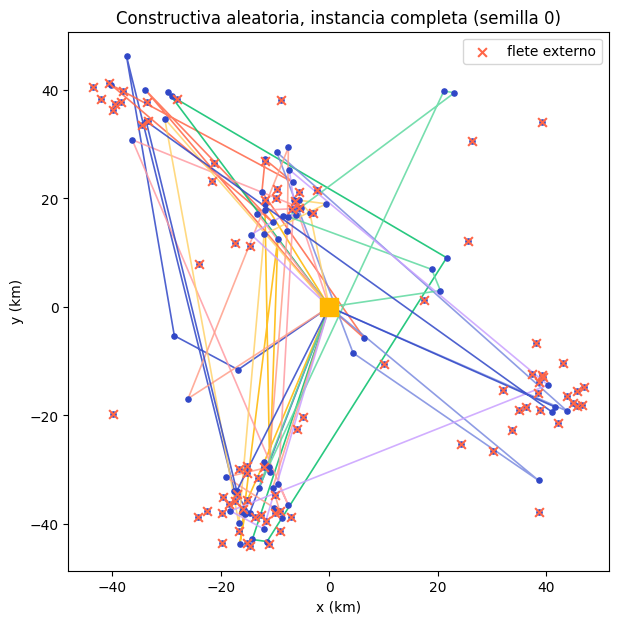

In [6]:
inst = instancia("completa")
sol = aleatoria(inst, 0)
print(describir(sol, inst))
dibujar(sol, inst, titulo="Constructiva aleatoria, instancia completa (semilla 0)")

### El escenario de la pregunta P3

`escenario_p3()` construye la instancia del escenario descrito en la pregunta P3 del dossier. La constructiva aleatoria también es factible en ella; úsenla como línea base del escenario.

In [7]:
inst = escenario_p3()
t0 = time.time(); sol = aleatoria(inst, 0); t = time.time() - t0
viol = verificar(sol, inst)
assert not viol, viol[:3]
print("Escenario P3, aleatoria (semilla 0):", describir(sol, inst))
registrar("escenario_p3", "aleatoria", evaluar(sol, inst)["costo"], t, 0)
SOLUCIONES["escenario_p3"] = {0: a_json(sol)}

Escenario P3, aleatoria (semilla 0): costo 9,009,720 | vehículos 10 | km 2,746.7 | puntos con flete externo 90


## 5. Tabla estándar de resultados

Cada corrida que reporten en el informe debe estar aquí: instancia, método, valor, tiempo y semilla (pautas U2-A3 a U2-A5). Usen `registrar(...)` después de cada corrida.

In [8]:
ver_tabla().groupby(["instancia", "metodo"])["valor"].agg(["count", "min", "mean"]).round(1)

,,count,min,mean
instancia,metodo,,,
completa,aleatoria,10,"8,603,435.0","8,981,095.0"
escenario_p3,aleatoria,1,"9,009,719.5","9,009,719.5"
intermedia,aleatoria,10,"1,744,826.5","1,981,668.0"
reducida,aleatoria,10,"219,980.0","250,919.3"


## 6. Su constructiva

Diseñen su propia constructiva respondiendo las cuatro preguntas de la receta. Pueden partir de la aleatoria y cambiar una respuesta a la vez (por ejemplo, el criterio: la mejor posición en lugar del final de la ruta). La única exigencia dura es que `verificar` devuelva una lista vacía en todas las instancias.

In [9]:
def mi_constructiva(inst, semilla=0):
    """Respondan aquí las cuatro preguntas de la receta (Sesión 10, paso 5):
    1) Unidad de decisión: qué se fija en cada paso.
    2) Orden: quién va primero (regla general: lo más restringido primero).
    3) Criterio: entre las opciones que no violan nada, cuál se elige.
    4) Qué hacer si no cabe: el recurso externo siempre está disponible y siempre es caro.
    """
    rng = random.Random(semilla)
    # Por ahora devuelve la aleatoria: reemplácenla por su propia regla.
    return aleatoria(inst, semilla)

for nombre in ("reducida", "completa"):
    inst = instancia(nombre)
    t0 = time.time(); sol = mi_constructiva(inst, 0); t = time.time() - t0
    viol = verificar(sol, inst)
    print(nombre, "->", "factible" if not viol else f"INFACTIBLE: {viol[:5]}")
    print("   ", describir(sol, inst), f"| tiempo {t:.3f} s")
    registrar(nombre, "mi_constructiva", evaluar(sol, inst)["costo"], t, 0, factible=not viol)


reducida -> factible
    costo 260,606 | vehículos 2 | km 334.7 | puntos con flete externo 0 | tiempo 0.000 s
completa -> factible
    costo 8,699,291 | vehículos 11 | km 3,024.0 | puntos con flete externo 84 | tiempo 0.001 s


## 7. Plantilla del modelo exacto

Aquí implementan el modelo que formularon en el paso 4 y lo resuelven en la instancia **reducida** (benchmark del paso 6a). La plantilla instala PuLP 3.3.2 (la versión 4.0, que Colab instala si no se indica otra, no trae el solver CBC y cambió la forma de crear variables, por eso se fija la versión y no se debe tocar esa línea), la resolución con límite de tiempo, la lectura del estado y el cálculo del gap; la formulación es de ustedes. Si prefieren OpenSolver, usen los CSV del dossier.

In [10]:
#@title Instalar PuLP 3.3.2 (no se toca)
import sys, subprocess
_r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--root-user-action=ignore", "pulp==3.3.2"], capture_output=True, text=True)
if _r.returncode != 0:
    print(_r.stderr); raise RuntimeError("No se pudo instalar PuLP 3.3.2: revise la conexión a internet de Colab y vuelva a ejecutar.")
import pulp
if not pulp.__version__.startswith("3."):
    raise RuntimeError(
        f"La sesión tiene cargado PuLP {pulp.__version__} y este cuaderno necesita PuLP 3.3.2. "
        "Vaya a Entorno de ejecución > Reiniciar sesión y luego a Entorno de ejecución > Ejecutar todas.")
print(f"Listo: PuLP {pulp.__version__}, solver CBC disponible: {bool(pulp.PULP_CBC_CMD(msg=False).available())}")

def gap(valor, referencia):
    """Gap porcentual de un valor respecto de una referencia (óptimo o mejor cota), para minimización."""
    return 100.0 * (valor - referencia) / abs(referencia)

def resolver(modelo, limite_s=600):
    """Resuelve con CBC con límite de tiempo y devuelve (estado, valor del objetivo, tiempo en s)."""
    t0 = time.time(); modelo.solve(pulp.PULP_CBC_CMD(timeLimit=limite_s, msg=False)); t = time.time() - t0
    return pulp.LpStatus[modelo.status], pulp.value(modelo.objective), t

inst_r = instancia("reducida")
# ---------- Modelo IP/MIP del paso 4: arcos dirigidos, binarias de ruta y de subcontratación ----------
modelo = pulp.LpProblem("benchmark_reducida", pulp.LpMinimize)

# --- 1. Conjuntos e índices (a partir de inst_r) ---
N = inst_r["ids"]                                           # clientes
V0 = [0] + N                                                # clientes y base (0)
A = [(i, j) for i in V0 for j in V0 if i != j]              # arcos dirigidos i→j
d = {i: PUNTOS[i]["demanda"] for i in N}                    # bidones del cliente i
s = {i: PUNTOS[i]["servicio_min"] for i in N}               # minutos de descarga en i
tv = {(i, j): minutos(i, j, inst_r) for i, j in A}          # minutos de viaje i→j
Q, L, K, F, c_km = inst_r["Q"], inst_r["L"], inst_r["K"], inst_r["F"], inst_r["c_km"]
f_fijo, f_unit = inst_r["flete_fijo"], inst_r["flete_unidad"]
def M_arco(i, j):
    """Cota grande del arco i→j, ajustada: es el máximo del lado izquierdo de su restricción de tiempo cuando el arco no se usa."""
    return tv[i, j] if i == 0 else L + tv[i, j]

# --- 2. Variables de decisión (incluidas las binarias) ---
x = pulp.LpVariable.dicts("x", A, cat="Binary")             # x[i,j] = 1 si un camión recorre el arco i→j
z = pulp.LpVariable.dicts("z", N, cat="Binary")             # z[i] = 1 si el cliente i va con transportista arrendado
T = {i: pulp.LpVariable(f"T_{i}", lowBound=0, upBound=L - s[i]) for i in N}  # minuto de inicio de la descarga en i desde la salida de la base; T_i + s_i <= L
u = pulp.LpVariable.dicts("u", N, lowBound=0, upBound=Q)    # bidones acumulados en el camión hasta i (incluido i)

# --- 3. Función objetivo ---
modelo += (F * pulp.lpSum(x[0, j] for j in N)                        # $ por camión que sale a ruta
           + c_km * pulp.lpSum(DIST[i][j] * x[i, j] for i, j in A)   # $ por km recorrido (incluye el regreso a la base)
           + pulp.lpSum((f_fijo + f_unit * d[i]) * z[i] for i in N)) # $ del flete externo por cliente

# --- 4. Restricciones (una familia por cada regla del dossier) ---
# Atención: cada cliente se atiende una vez y completo, con camión propio (una entrada y una salida) o con flete externo
for i in N:
    modelo += pulp.lpSum(x[j, i] for j in V0 if j != i) + z[i] == 1, f"llega_{i}"
    modelo += pulp.lpSum(x[i, j] for j in V0 if j != i) + z[i] == 1, f"sale_{i}"
# Flota: a lo más K rutas por día; cada ruta que sale de la base vuelve a ella
modelo += pulp.lpSum(x[0, j] for j in N) <= K, "flota"
modelo += pulp.lpSum(x[0, j] for j in N) == pulp.lpSum(x[i, 0] for i in N), "vuelta_a_base"
# Capacidad (MTZ): la carga acumulada crece en d_j al entrar a j y nunca supera Q
for i in N:
    modelo += u[i] >= d[i], f"carga_min_{i}"
for i in N:
    for j in N:
        if i != j:
            modelo += u[j] >= u[i] + d[j] - Q * (1 - x[i, j]), f"carga_{i}_{j}"
# Jornada: viaje desde la base, descarga en cada punto, regreso a la base; no puede superar L
for j in N:
    modelo += T[j] >= tv[0, j] - M_arco(0, j) * (1 - x[0, j]), f"inicio_{j}"
    modelo += T[j] + s[j] + tv[j, 0] <= L + M_arco(j, 0) * (1 - x[j, 0]), f"fin_{j}"
for i in N:
    for j in N:
        if i != j:
            modelo += T[j] >= T[i] + s[i] + tv[i, j] - M_arco(i, j) * (1 - x[i, j]), f"tiempo_{i}_{j}"

binarias = sum(1 for v in modelo.variables() if v.cat == pulp.LpInteger and v.upBound == 1)
print(f"Modelo: {len(modelo.variables())} variables ({binarias} binarias), {len(modelo.constraints)} restricciones")
estado, valor, t = resolver(modelo, 600)
# PuLP reporta "Optimal" también cuando CBC se detiene por tiempo con una solución: el estado que certifica es sol_status
certificado = modelo.sol_status == pulp.LpSolutionOptimal
print(estado, valor, f"{t:.1f} s", "| óptimo certificado" if certificado else "| NO certificado: CBC se detuvo por límite de tiempo")
assert estado == "Optimal", estado
registrar("reducida", "exacto CBC", valor, t, None, notas="óptimo certificado" if certificado else "límite de tiempo: solución sin cota probada")

# Comprobación: se traduce la solución del modelo al formato de la sección 2 y se pasa por verificar() y evaluar().
# El costo debe coincidir con el valor del objetivo.
def activo(v):
    return (v.value() or 0) > 0.5
rutas_exactas = []
for j in N:
    if activo(x[0, j]):
        ruta = [j]
        while True:
            k = next(k for k in V0 if k != ruta[-1] and activo(x[ruta[-1], k]))
            if k == 0:
                break
            ruta.append(k)
        rutas_exactas.append(ruta)
sol_exacta = dict(rutas=rutas_exactas, externos=[i for i in N if activo(z[i])])
assert not verificar(sol_exacta, inst_r), verificar(sol_exacta, inst_r)
assert abs(evaluar(sol_exacta, inst_r)["costo"] - valor) < 0.01, (evaluar(sol_exacta, inst_r)["costo"], valor)
print("Solución exacta:", describir(sol_exacta, inst_r))
print("Rutas:", sol_exacta["rutas"], "| con flete externo:", sol_exacta["externos"])


In [ ]:
# ===================== Certificación exacta independiente (instancia reducida) =====================
# Programación dinámica sobre subconjuntos (Held-Karp), sin CBC. Para cada subconjunto S y último cliente j guarda la
# distancia mínima de un camino desde la base que visita exactamente S. Como la descarga de S es la misma para todo
# camino, la duración de la ruta crece con la distancia: el camino más corto es también el más factible.
# Luego combina hasta K rutas disjuntas. Solo sirve para instancias pequeñas (n <= 20).
def optimo_dp(inst):
    ids = inst["ids"]; n = len(ids); K = inst["K"]; Q = inst["Q"]; L = inst["L"]
    if n > 20:
        raise ValueError("La DP por subconjuntos solo se usa en la instancia reducida.")
    dem = [PUNTOS[i]["demanda"] for i in ids]; srv = [PUNTOS[i]["servicio_min"] for i in ids]
    full = (1 << n) - 1; INF = float("inf")
    load = [0] * (1 << n); serv = [0] * (1 << n); flete = [0.0] * (1 << n)
    for S in range(1, 1 << n):
        b = (S & -S).bit_length() - 1; R = S & (S - 1)            # R = S sin su bit más bajo
        load[S] = load[R] + dem[b]; serv[S] = serv[R] + srv[b]; flete[S] = flete[R] + costo_flete(ids[b], inst)
    best = [[INF] * n for _ in range(1 << n)]; par = [[None] * n for _ in range(1 << n)]
    for j in range(n):
        best[1 << j][j] = DIST[0][ids[j]]
    for S in range(1, 1 << n):
        for j in range(n):
            if not (S >> j) & 1 or best[S][j] == INF:
                continue
            for k in range(n):
                T_ = S | (1 << k)
                if (S >> k) & 1 or load[T_] > Q:
                    continue
                c = best[S][j] + DIST[ids[j]][ids[k]]
                if c < best[T_][k]:
                    best[T_][k] = c; par[T_][k] = j
    # ruta factible con conjunto S: carga <= Q y duración (viaje + descarga + regreso) <= L
    ruta_km = [INF] * (1 << n); ruta_fin = [None] * (1 << n)
    for S in range(1, 1 << n):
        for j in range(n):
            if (S >> j) & 1 and best[S][j] < INF:
                km = best[S][j] + DIST[ids[j]][0]
                dur = km / inst["vel"] * 60.0 + serv[S]
                if load[S] <= Q and dur <= L + 1e-9 and km < ruta_km[S]:
                    ruta_km[S] = km; ruta_fin[S] = j
    # valor de cada ruta: costo fijo + costo por km, menos el flete externo que evita (el flete se suma aparte al final)
    w = [inst["F"] + inst["c_km"] * ruta_km[S] - flete[S] if ruta_km[S] < INF else INF for S in range(1 << n)]
    # g[mask] = mínimo de la suma de w sobre a lo más k rutas disjuntas contenidas en mask
    g_prev = [0.0] * (1 << n); args = []
    for _ in range(K):
        g = g_prev[:]; arg = [0] * (1 << n)
        for mask in range(1, 1 << n):
            S = mask
            while S:
                if w[S] < INF and w[S] + g_prev[mask ^ S] < g[mask]:
                    g[mask] = w[S] + g_prev[mask ^ S]; arg[mask] = S
                S = (S - 1) & mask
        args.append(arg); g_prev = g
    # reconstrucción de las rutas elegidas
    mask, elegidas = full, []
    for arg in reversed(args):
        if arg[mask]:
            elegidas.append(arg[mask]); mask ^= arg[mask]
    def ruta_de(S):
        j = ruta_fin[S]; seq = []
        while True:
            seq.append(ids[j])
            if bin(S).count("1") == 1:
                break
            p = par[S][j]; S ^= 1 << j; j = p
        return seq[::-1]
    rutas = [ruta_de(S) for S in elegidas]
    externos = [i for i in ids if i not in {c for r in rutas for c in r}]
    sol = dict(rutas=rutas, externos=externos)
    return ext_total(inst) + g_prev[full], sol

def ext_total(inst):
    return sum(costo_flete(i, inst) for i in inst["ids"])

t0 = time.time()
costo_dp, sol_dp = optimo_dp(inst_r)
t_dp = time.time() - t0
assert not verificar(sol_dp, inst_r), verificar(sol_dp, inst_r)
assert abs(evaluar(sol_dp, inst_r)["costo"] - costo_dp) < 0.01, (evaluar(sol_dp, inst_r)["costo"], costo_dp)
print(f"DP exacta (reducida): {describir(sol_dp, inst_r)} | tiempo {t_dp:.2f} s")
print("Rutas:", sol_dp["rutas"], "| con flete externo:", sol_dp["externos"])
registrar("reducida", "exacto DP subconjuntos", costo_dp, t_dp, None, notas="óptimo certificado")
print(f"Brecha del CBC respecto del óptimo DP: {gap(valor, costo_dp):.3f} %")


## 8. Guardar resultados

Regla de evidencia: todo número del informe debe poder regenerarse con este cuaderno. Guarden la tabla estándar y las soluciones, y anoten las semillas.

In [11]:
# Tabla estándar y soluciones de la línea base, en archivos (en Colab quedan en el panel de archivos, a la izquierda).
ver_tabla().to_csv(f"tabla_estandar_{DATA['codigo']}.csv", index=False)
json.dump(SOLUCIONES, open(f"soluciones_aleatoria_{DATA['codigo']}.json", "w"))
print("Guardados: tabla_estandar_%s.csv y soluciones_aleatoria_%s.json" % (DATA["codigo"], DATA["codigo"]))
ver_tabla().tail(8)


Guardados: tabla_estandar_D03.csv y soluciones_aleatoria_D03.json


,dossier,instancia,metodo,valor,tiempo_s,semilla,factible,notas
25,D03,completa,aleatoria,"8,862,836.0",0.0,5,True,
26,D03,completa,aleatoria,"9,056,147.0",0.0,6,True,
27,D03,completa,aleatoria,"9,122,151.5",0.0,7,True,
28,D03,completa,aleatoria,"9,733,928.0",0.0,8,True,
29,D03,completa,aleatoria,"8,630,759.0",0.0,9,True,
30,D03,escenario_p3,aleatoria,"9,009,719.5",0.0,0,True,
31,D03,reducida,mi_constructiva,"260,606.0",0.0,0,True,
32,D03,completa,mi_constructiva,"8,699,291.0",0.0,0,True,
